# H2 · Un modelo más fuerte sube el techo de Stage 2 cuando recibe la respuesta correcta

**Hipótesis.** Los 17,8 puntos que el paper atribuye a "pérdida propia de la segunda etapa"
(brazo B: el ground truth como entrada de Stage 2) son una limitación de Flash, y un modelo
más fuerte los recupera.

**Veredicto: rechazada.** Claude Opus queda igual que Flash (82,89 frente a 83,18 y 81,16).
Gemini Pro queda *por debajo*: 71,49 y 68,12 en sus dos corridas. Ningún modelo pasa de ~83.

**Lo inesperado.** Pro no transporta la respuesta que recibe: añade más de cien aristas e
inventa servicios. El porqué está en H4 y H5.

## Archivos usados, cómo se generaron y dónde quedaron

| corrida | entrada de Stage 2 | cómo se generó | dónde quedó |
|---|---|---|---|
| Flash | `lab_workspace/<vid>/world_model_oracle_gt.json` + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt` (28 de agosto) | `reports/ablation/2026-08-28_0315_…_oracle-oracle_gt/` |
| Flash · réplica 2 | la misma | la misma, con `--replicate 2` | `reports/ablation/2026-08-28_2211_…_oracle-oracle_gt_rep2/` |
| Claude Opus 5.5 | la misma | `scripts/ablation/claude_panel.py --oracle oracle_gt export`, `run`, `evaluate` | `reports/claude_oracle_gt/` |
| Pro | la misma | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt --model gemini-3.1-pro-preview --out …` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt/` |
| Pro · réplica 2 | la misma | la misma, con `--replicate 2` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_rep2/` |

El World Model oráculo sale de `scripts/ablation/build_oracle_world_models.py` (conversión
determinista del graphml, techo de copia 100/100) y sus hashes están en
`ara/evidence/oracle/brazo_b_world_models_p30.json`. El de `ww5fiygF6eg` faltaba en
`lab_workspace` y se restauró; su sha256 coincide con el del ledger.
Figuras de este notebook: `hipotesis/figuras/H2_*.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()

B = ["B_flash", "B_flash_rep2", "B_claude", "B_pro", "B_pro_rep2"]
n, distintas = c.verificar(B)
print(f"Control: el F1 de aristas recalculado aquí coincide con el del evaluador en {n - distintas} de {n} filas.")
c.tabla_resumen(B)

Control: el F1 de aristas recalculado aquí coincide con el del evaluador en 150 de 150 filas.


corrida,F1 servicios,F1 aristas,aristas / GT,faltan,sobran,precisión,recall,servicios inventados,videos perfectos,carpeta
Gemini 3.6 Flash,99.70,83.18,10.00 / 12.03,86,25,91.7,76.2,1,3,reports/ablation/2026-08-28_0315_STAGE2_V6_CORRECTED_cell9_p30_oracle-oracle_gt
Gemini 3.6 Flash · réplica 2,99.44,81.16,9.93 / 12.03,95,32,89.3,73.7,0,4,reports/ablation/2026-08-28_2211_STAGE2_V6_CORRECTED_cell9_p30_oracle-oracle_gt_rep2
Claude Opus 5.5,98.71,82.89,11.60 / 12.03,69,56,83.9,80.9,3,5,reports/claude_oracle_gt
Gemini 3.1 Pro,93.54,71.49,12.63 / 12.03,95,113,70.2,73.7,19,2,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt
Gemini 3.1 Pro · réplica 2,92.43,68.12,12.20 / 12.03,112,117,68.0,69.0,22,1,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_rep2


## 1 · Con la respuesta delante, nadie pasa de ~83

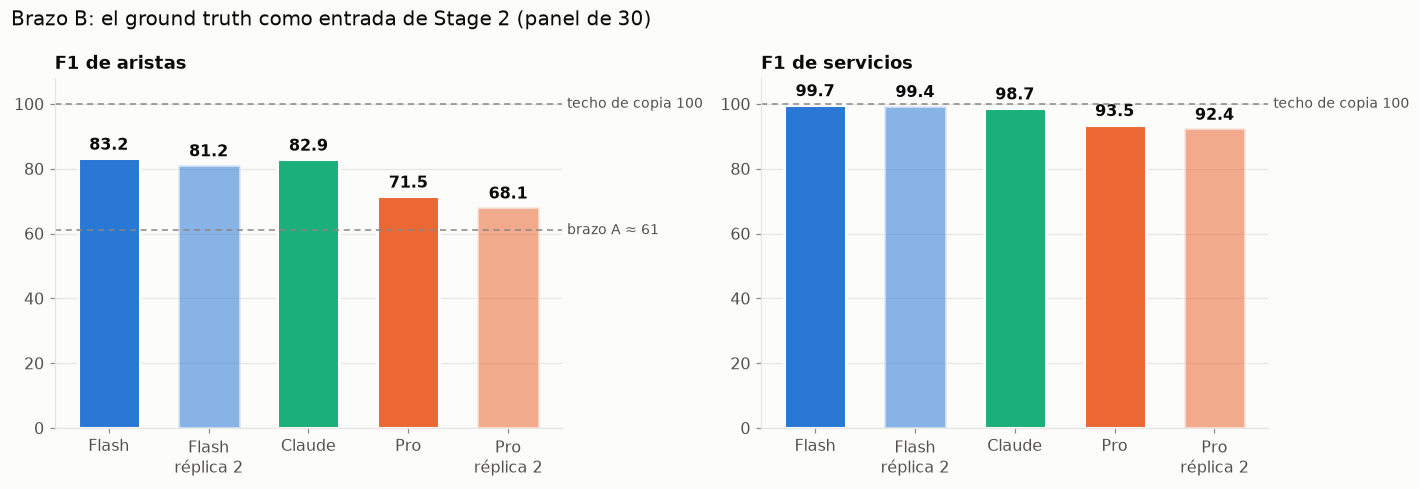

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
c.barras(ax[0], B, "edge", "F1 de aristas", ref={"techo de copia 100": 100, "brazo A ≈ 61": 61})
c.barras(ax[1], B, "svc", "F1 de servicios", ref={"techo de copia 100": 100})
fig.suptitle("Brazo B: el ground truth como entrada de Stage 2 (panel de 30)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H2_medias")

## 2 · Diferencias pareadas contra Flash

La franja gris es lo que Flash difiere de sí mismo entre sus dos corridas.

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Gemini 3.6 Flash · réplica 2 − Gemini 3.6 Flash,-2.02,"[-4.36, +0.13]",6 / 14 / 10,0.115
Claude Opus 5.5 − Gemini 3.6 Flash,-0.30,"[-2.97, +2.28]",11 / 8 / 11,0.648
Gemini 3.1 Pro − Gemini 3.6 Flash,-11.70,"[-18.10, -5.83]",7 / 21 / 2,0.013
Gemini 3.1 Pro · réplica 2 − Gemini 3.6 Flash,-15.06,"[-21.04, -9.60]",4 / 23 / 3,0.000


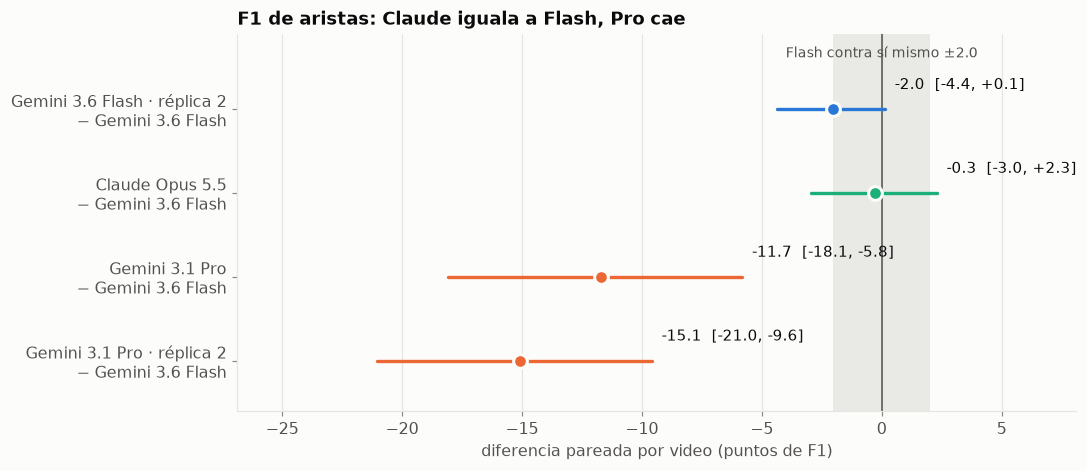

In [3]:
pares = [("B_flash", "B_flash_rep2"), ("B_flash", "B_claude"), ("B_flash", "B_pro"), ("B_flash", "B_pro_rep2")]
ruido = abs(c.pareado("B_flash", "B_flash_rep2")["dif"])
fig, ax = plt.subplots(figsize=(10, 4.4))
c.bosque(ax, pares, titulo="F1 de aristas: Claude iguala a Flash, Pro cae", banda=ruido, banda_txt="Flash contra sí mismo")
fig.tight_layout()
c.guardar(fig, "H2_diferencias")
c.tabla_pareada(pares)

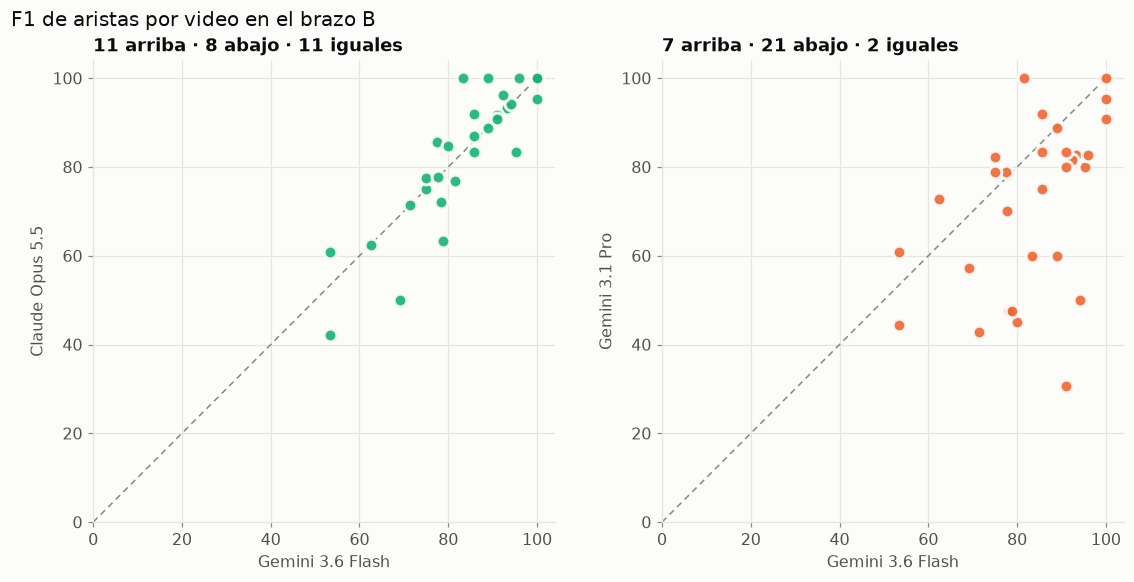

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 5.2))
c.dispersion(ax[0], "B_flash", "B_claude")
c.dispersion(ax[1], "B_flash", "B_pro")
fig.suptitle("F1 de aristas por video en el brazo B", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H2_por_video")

## 3 · En qué se equivoca cada uno

Flash y Claude casi no añaden nada: pierden aristas. Pro pierde las mismas y además añade
más de cien que no están en la referencia.

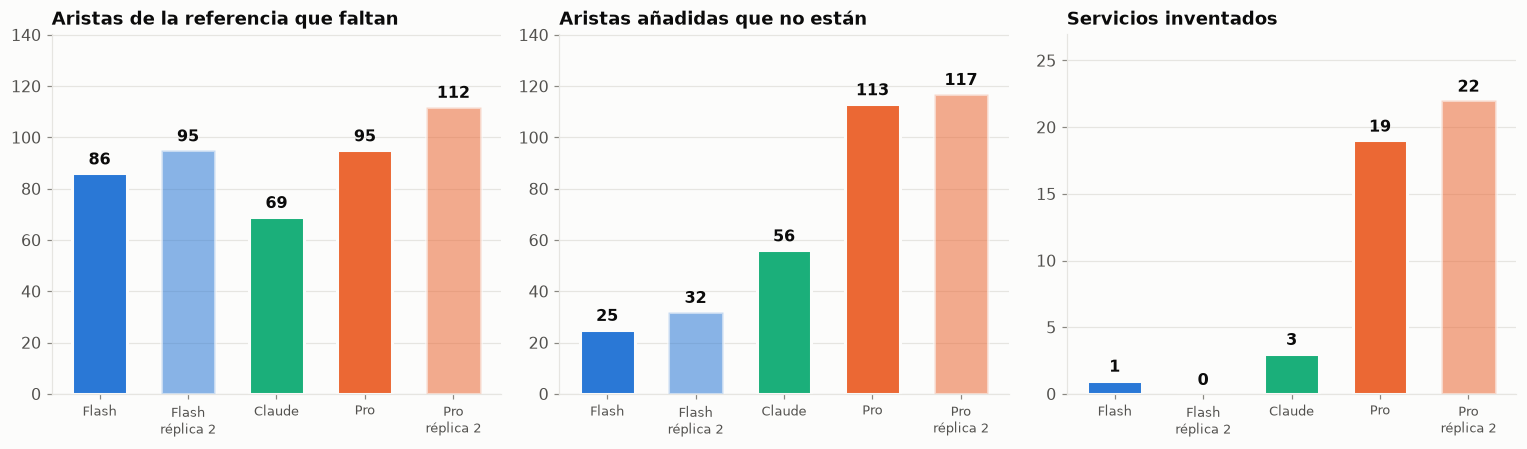

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
c.barras(ax[0], B, "faltan", "Aristas de la referencia que faltan", ymax=130)
c.barras(ax[1], B, "sobran", "Aristas añadidas que no están", ymax=130)
c.barras(ax[2], B, "inventados", "Servicios inventados", ymax=25)
for a in ax:
    a.tick_params(axis="x", labelsize=8.5)
fig.tight_layout()
c.guardar(fig, "H2_errores")

## 4 · Un video de ejemplo

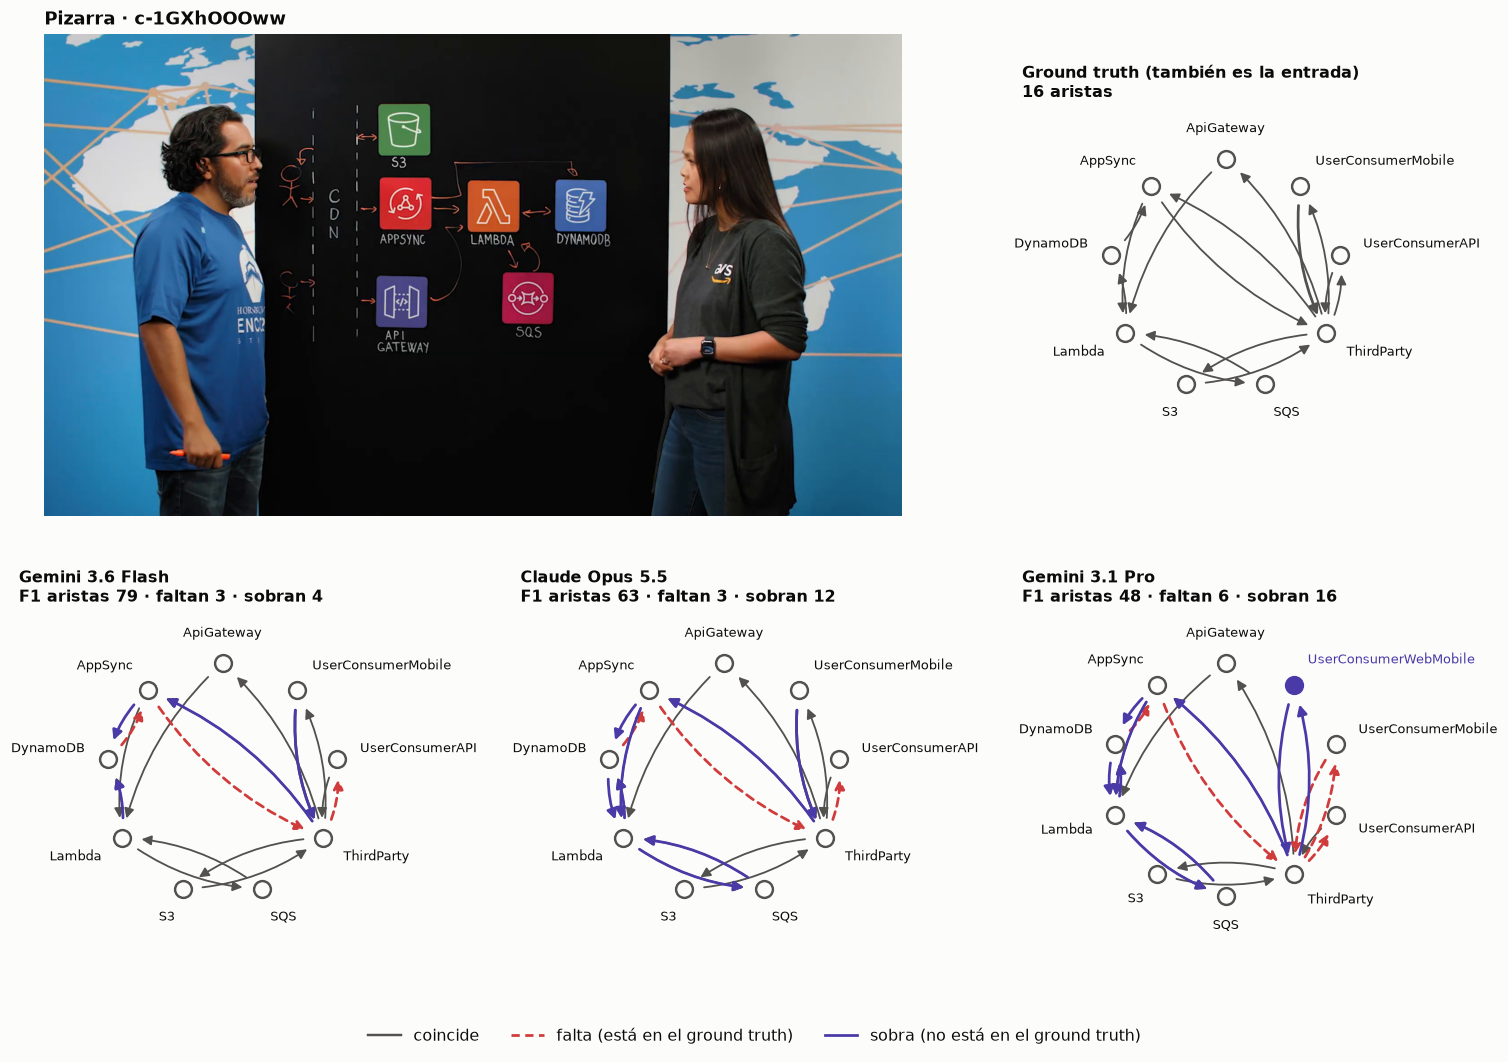

In [6]:
vid = "c-1GXhOOOww"
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 3)
c.pizarra(fig.add_subplot(gs[0, :2]), vid)
c.grafo(fig.add_subplot(gs[0, 2]), vid, titulo="Ground truth (también es la entrada)")
for i, k in enumerate(["B_flash", "B_claude", "B_pro"]):
    c.grafo(fig.add_subplot(gs[1, i]), vid, c.filas(k)[vid], c.etiqueta(k))
c.leyenda_grafo(fig)
fig.tight_layout()
c.guardar(fig, "H2_ejemplo")

## Qué aporta al paper

La "pérdida propia de la segunda etapa" no es una limitación de Flash: un modelo más fuerte de
otro proveedor pierde lo mismo. El techo no sube con el modelo, pero sí puede bajar.
Salvedad: Claude tiene una sola corrida y sin temperatura fija.